# 04. 플로어 가격 계산

**목표:** 지금 시장 금리 기준으로, 발행사가 금리 플로어를 사려면 **얼마를 내야 하는지** 가격표를 만든다.

## 플로어란
- **금리 플로어**: 기준금리(SOFR)가 행사가 K보다 **낮아지면** 그 차이만큼 돈을 받는 계약. 금리 하락에 대한 보험이다.
- **플로어렛**: 플로어를 분기 단위로 쪼갠 조각 하나. 분기마다 정산 금액 = 명목금액 × 0.25년 × max(K − 그 분기 SOFR, 0)
- **플로어 가격** = 모든 플로어렛 가격의 합. 3년 플로어는 분기 12개짜리 플로어렛 묶음이다.
- **프리미엄**: 플로어를 살 때 처음에 한 번 내는 가격.

## 계산 순서
1. 현재 미국채 수익률곡선 → **할인계수**(미래 1원의 오늘 가치)와 **분기별 선도금리**(지금 시장이 "그 분기에 적용될 금리"로 보는 값)
2. 분기마다 **바슐리에 공식**으로 플로어렛 가격 → 합쳐서 플로어 가격
3. 행사가 K × 만기 × σ 가격표
4. 검증: 플로어 − 캡 = 리시버 스왑

## 1. 준비
이 셀이 하는 일: 도구를 불러오고, 경로와 그래프 설정을 한다.

In [1]:
import sys
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

### 가격 계산 함수 불러오기
이 셀이 하는 일: `src/floor_pricing.py`에 만들어 둔 함수를 불러오고, 핵심 두 함수의 코드를 출력해서 본다. (다음 단계에서 전략별 비용을 계산할 때도 같은 함수를 쓴다)

In [2]:
from src.floor_pricing import build_curve, bachelier, price_floor, equivalent_sigma, monthly_forwards, TAU
from src.rate_model import simulate_market_consistent

print(inspect.getsource(bachelier))
print(inspect.getsource(price_floor))

def bachelier(F, K, sigma, T, kind="floor"):
    """바슐리에(정규) 모형의 옵션 값 (할인 전, % 단위).

    floor(풋):  (K − F)·Φ(d) + σ√T·φ(d),  d = (K − F) / (σ√T)
    cap(콜):    (F − K)·Φ(−d) + σ√T·φ(d)
    """
    s = sigma * np.sqrt(T)
    d = (K - F) / s
    if kind == "floor":
        return (K - F) * norm.cdf(d) + s * norm.pdf(d)
    return (F - K) * norm.cdf(-d) + s * norm.pdf(d)

def price_floor(curve, K, maturity, sigma, notional=100, tau=TAU, a=None):
    """만기 maturity(년)까지의 분기 플로어렛을 모두 더해 플로어·캡·리시버 스왑 가치를 낸다.

    SOFR 플로어는 분기 동안의 SOFR를 복리로 평균해 분기 끝에 정산한다(후취).
    분기 중에도 금리가 움직이므로, 옵션 만기를 '분기 시작 + 분기 길이의 1/3'로 잡아 그 몫을 반영한다.
    a: 주면 플로어렛마다 등가 σ(평균회귀 반영)를 쓴다 (메인). None이면 σ를 그대로 쓴다 (부록).
    반환: (요약 딕셔너리, 플로어렛 표)
    """
    legs = curve[curve["end"] <= maturity + 1e-9].copy()
    legs["T_eff"] = legs["start"] + tau / 3
    legs["sigma"] = equivalent_sigma(legs["T_eff"], a, sigma) if a is not None else sigma
    scale = notional / 100 * tau * legs["D_end"]            # 명목 × 기간 × 할인 (금리 % → 금액

## 2. 현재 수익률곡선
이 셀이 하는 일: 8개 만기 국채 금리가 모두 있는 **가장 최근 날짜**의 수익률곡선과, 같은 날 SOFR를 가져온다.

In [3]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")

CURVE_IDS = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
MATURITIES = np.array([1 / 12, 0.25, 0.5, 1, 2, 3, 5, 10])   # 년

curve_row = rates[CURVE_IDS].dropna().iloc[-1]
curve_date = curve_row.name
sofr_today = rates.loc[curve_date, "SOFR"]

print(f"곡선 날짜: {curve_date:%Y-%m-%d} | 같은 날 SOFR: {sofr_today:.2f}%")
pd.DataFrame({"만기(년)": MATURITIES, "국채 수익률(%)": curve_row.values}, index=CURVE_IDS).T

곡선 날짜: 2026-10-26 | 같은 날 SOFR: 3.93%


,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS10
만기(년),0.0833,0.2500,0.5000,1.0000,2.0000,3.0000,5.0000,10.0000
국채 수익률(%),4.1100,4.2200,4.3500,4.4700,4.6800,4.7900,4.8400,5.0000


### 국채와 SOFR의 차이 (한계 확인)
SOFR 플로어의 가격은 원래 **SOFR 스왑 곡선**으로 매겨야 한다. 무료로 구하기 어려워서 **국채 곡선을 대신** 쓴다.

이 셀이 하는 일: 단기 국채 금리와 SOFR의 차이를 계산해, 이 대용이 얼마나 어긋나는지 본다.

In [4]:
gap = pd.Series({
    "1개월 국채 − SOFR (bp)": (curve_row["DGS1MO"] - sofr_today) * 100,
    "3개월 국채 − SOFR (bp)": (curve_row["DGS3MO"] - sofr_today) * 100,
}, name=f"{curve_date:%Y-%m-%d}")
gap.to_frame()

,2026-10-26
1개월 국채 − SOFR (bp),18.0000
3개월 국채 − SOFR (bp),29.0000


**읽는 법**: 지금은 단기 국채가 SOFR보다 **약 20~30bp 높다.** 국채 곡선을 그대로 쓰면 선도금리가 SOFR 기준보다 그만큼 높게 잡혀서, 금리가 K 아래로 내려갈 가능성이 작게 계산된다. 그러면 **플로어 가격이 실제보다 싸게** 나온다.

### 보정 방법 (메인 설정)
- **1개월 국채 − SOFR 차이(약 18bp)를 곡선 전체에서 뺀다.** 가장 짧은 만기라 기간 프리미엄이 가장 적게 섞여 있고, 빼고 나면 **첫 달 선도금리가 현재 SOFR와 같아져서** 곡선의 출발점이 맞는다.
- 3개월 국채 기준(약 29bp)으로 빼면 가격이 조금 더 비싸진다. 5번 비교표에서 참고로 보여준다.
- 한계: 모든 만기에서 국채−SOFR 차이가 같다고 가정하는 **간단 보정**이다.

In [5]:
SHIFT_BP = gap["1개월 국채 − SOFR (bp)"]
print(f"곡선 보정: 모든 만기에서 {SHIFT_BP:.0f}bp를 뺀다")

곡선 보정: 모든 만기에서 18bp를 뺀다


## 3. 할인계수와 분기 선도금리

- **할인계수 D(t)**: t년 뒤에 받을 1원이 오늘 얼마의 가치인지. 금리가 4.5%면 1년 뒤 1원 ≈ 오늘 0.956원.
- **선도금리 F**: 오늘 시장 금리로 계산한 "미래 어느 분기에 적용될 금리". 두 시점의 할인계수 비율로 구한다.

$$F_i = \frac{1}{0.25}\left(\frac{D(t_{i-1})}{D(t_i)} - 1\right)$$

직관: "1년 동안 맡기는 것"과 "9개월 맡기고 남은 3개월을 다시 맡기는 것"의 결과가 같아야 한다. 그 조건을 만족하는 마지막 3개월의 금리가 선도금리다.

### 보간: 직선 대신 PCHIP
국채 금리는 8개 만기에만 있어서, 그 사이(예: 1.25년) 값은 **이어 붙여서(보간)** 구해야 한다.
- **직선 보간**: 점과 점을 자로 잇는다. 간단하지만 만기 지점(예: 2년)에서 기울기가 갑자기 바뀌어 **선도금리가 계단처럼 꺾인다.**
- **PCHIP 보간**: 점들을 지나면서 **꺾이지 않게 부드럽게** 잇는 방법. 점과 점 사이에서 원래 값보다 튀어 오르거나 내려가지도 않는다. 선도금리가 매끄럽게 나온다.

### 메인 곡선 만들기
이 셀이 하는 일: **보정(−18bp) + PCHIP**으로 3년치 분기 할인계수와 선도금리를 계산한다. 이것이 메인 가격 계산에 쓰는 곡선이다.

In [6]:
curve = build_curve(curve_row.values, MATURITIES, horizon=3.0, shift_bp=SHIFT_BP, method="pchip")
curve

,start,end,zero_end,D_end,forward
분기,,,,,
1,0.0000,0.2500,4.0197,0.9900,4.0400
2,0.2500,0.5000,4.1271,0.9796,4.2570
3,0.5000,0.7500,4.1917,0.9691,4.3443
4,0.7500,1.0000,4.2446,0.9584,4.4278
5,1.0000,1.2500,4.3012,0.9477,4.5531
6,1.2500,1.5000,4.3573,0.9367,4.6651
7,1.5000,1.7500,4.4085,0.9258,4.7434
8,1.7500,2.0000,4.4501,0.9148,4.7696
9,2.0000,2.2500,4.4848,0.9040,4.7905


### 보정 전후 비교
이 셀이 하는 일: 세 가지 곡선의 분기 선도금리를 한 그래프에 그린다.
- 보정 전 (직선 보간) → PCHIP만 적용 → **보정 + PCHIP (메인)**

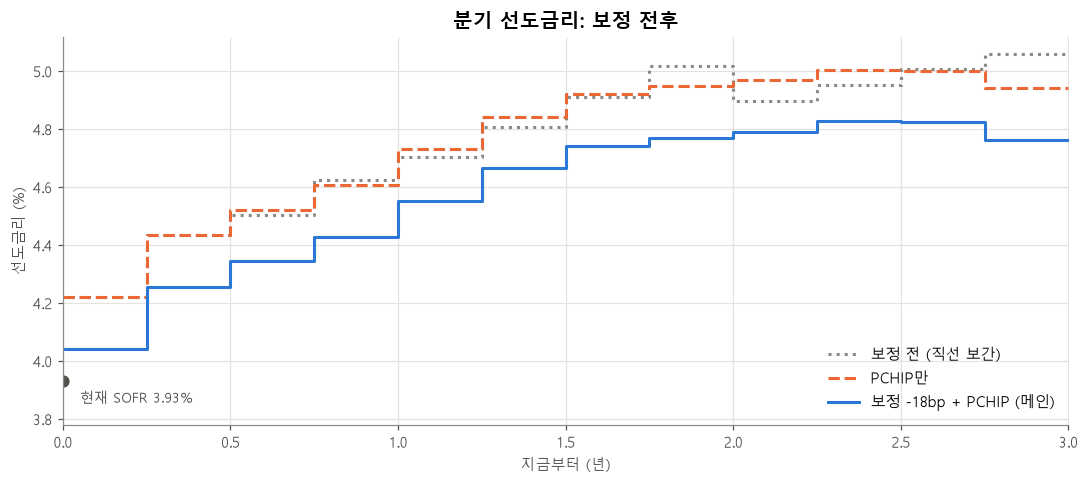

첫 분기 선도금리: 보정 전 4.22% → 메인 4.04%
2년 전후 분기: 직선 5.02% → 4.90% | PCHIP 4.77% → 4.79%


In [7]:
curve_linear = build_curve(curve_row.values, MATURITIES, horizon=3.0)
curve_pchip = build_curve(curve_row.values, MATURITIES, horizon=3.0, method="pchip")

def step_xy(c):
    # 분기마다 평평한 계단 모양으로 그리기 위한 x, y
    return np.r_[c["start"], 3.0], np.r_[c["forward"], c["forward"].iloc[-1]]

fig, ax = plt.subplots()
for c, color, style, label in [
    (curve_linear, MUTED, ":", "보정 전 (직선 보간)"),
    (curve_pchip, COLORS[1], "--", "PCHIP만"),
    (curve, COLORS[0], "-", f"보정 -{SHIFT_BP:.0f}bp + PCHIP (메인)"),
]:
    x, y = step_xy(c)
    ax.step(x, y, where="post", color=color, linestyle=style, linewidth=2, label=label)
ax.plot(0, sofr_today, "o", color=TEXT_SUB, markersize=7)
ax.annotate(f" 현재 SOFR {sofr_today:.2f}%", (0, sofr_today), xytext=(8, -14), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_xlim(0, 3)
ax.set_ylim(bottom=sofr_today - 0.15)   # 현재 SOFR 글씨가 잘리지 않게 아래 여백
ax.set_title("분기 선도금리: 보정 전후")
ax.set_xlabel("지금부터 (년)")
ax.set_ylabel("선도금리 (%)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_forward_curves.png", dpi=200)
plt.show()

print(f"첫 분기 선도금리: 보정 전 {curve_linear['forward'].iloc[0]:.2f}% → 메인 {curve['forward'].iloc[0]:.2f}%")
print(f"2년 전후 분기: 직선 {curve_linear['forward'].iloc[7]:.2f}% → {curve_linear['forward'].iloc[8]:.2f}% | "
      f"PCHIP {curve['forward'].iloc[7]:.2f}% → {curve['forward'].iloc[8]:.2f}%")

**읽는 법**
- **PCHIP**: 직선 보간 때 2년 지점에서 생기던 꺾임(약 5.02% → 4.90%)이 사라지고 선도금리가 매끄럽게 이어진다.
- **보정**: 곡선 전체가 18bp 내려간다. 첫 분기 선도금리가 약 4.04%로, 현재 SOFR(3.93%)와 국채 곡선(4.22%) 사이에 온다.
- 메인 시나리오는 **시장 일치 모형**(경로 평균 = 이 선도금리)이다. 그래서 이전에 걱정했던 "시나리오는 금리 하락, 가격은 금리 상승" 같은 기준 차이가 없다. (Vasicek b 기준 비교는 부록용으로 03번에 있다)

## 4. 바슐리에 공식으로 플로어렛 가격 매기기

**바슐리에(정규) 모형**: 금리가 앞으로 **정규분포**로 퍼진다고 보고 옵션 가격을 계산하는 공식. 블랙 모형(로그정규)과 달리 금리가 0 근처이거나 음수여도 쓸 수 있고, σ를 %p(= bp) 단위로 쓴다. 03번 Vasicek의 σ(0.64%p/√년)를 그대로 넣을 수 있다.

$$\text{플로어렛} = N \times 0.25 \times D(t_i) \times \Big[(K - F)\,\Phi(d) + \sigma\sqrt{T}\,\varphi(d)\Big], \quad d = \frac{K - F}{\sigma\sqrt{T}}$$

| 기호 | 뜻 |
|---|---|
| N × 0.25 × D | 명목금액 × 분기 길이 × 할인계수 (금리 %를 오늘 금액으로 바꾸는 부분) |
| K − F | 행사가가 선도금리보다 얼마나 높은지 (높을수록 '돈이 되는' 플로어) |
| σ√T | 정산 때까지 금리가 퍼질 수 있는 폭 (1 표준편차) |
| Φ, φ | 표준정규분포의 누적확률, 밀도 |

- 직관: 대괄호 안은 "**K − SOFR가 양수일 때의 평균 이익**"이다. 첫째 항은 지금 선도금리 기준 이익, 둘째 항은 금리가 흔들려서 생기는 **추가 기회의 값**(시간가치)이다.
- **T(옵션 만기)**: SOFR 플로어는 분기 동안의 SOFR를 복리로 평균해 **분기 끝에** 정산한다. 분기 중에도 금리가 움직이므로, T를 '분기 시작 + 분기 길이의 1/3'로 잡아 그 몫을 반영한다. (평균의 변동성은 하루치 변동성의 약 1/3이라는 근사)
- **σ (메인: 등가 σ)**: 메인 시나리오(시장 일치 모형)의 금리 충격은 **평균회귀**를 해서, T년 뒤 퍼짐이 σ√T보다 조금 작다. 시나리오와 가격이 **같은 퍼짐**을 쓰도록 플로어렛마다 아래 **등가 σ**를 넣는다. (9번에서 자세히)

$$\sigma_{\text{등가}}(T) = \sigma\sqrt{\frac{1 - e^{-2aT}}{2aT}}, \qquad \sigma = 0.64,\; a = 0.093$$

### 예시: 3년, K 3.5% 플로어의 분기별 조각 (메인 설정)
이 셀이 하는 일: 03번 추정값(a, σ)을 정하고, 플로어 하나를 12개 플로어렛으로 나눠 각각의 가격을 표로 본다.

In [8]:
A, SIGMA = 0.093, 0.64   # 03번 노트북 추정값 (평균회귀 속도, 변동성)

example, legs = price_floor(curve, K=3.5, maturity=3, sigma=SIGMA, a=A)

legs_view = legs[["start", "end", "forward", "D_end", "T_eff", "sigma", "floorlet"]].copy()
legs_view.columns = ["시작(년)", "끝(년)", "선도금리(%)", "할인계수", "옵션만기 T", "등가 σ", "플로어렛 가격"]
print(f"플로어 가격(명목 100) = {example['floor']:.4f}  (= {example['floor'] * 100:.2f}bp)")
legs_view

플로어 가격(명목 100) = 0.0455  (= 4.55bp)


,시작(년),끝(년),선도금리(%),할인계수,옵션만기 T,등가 σ,플로어렛 가격
분기,,,,,,,
1,0.0000,0.2500,4.0400,0.9900,0.0833,0.6375,0.0000
2,0.2500,0.5000,4.2570,0.9796,0.3333,0.6302,0.0006
3,0.5000,0.7500,4.3443,0.9691,0.5833,0.6230,0.0018
4,0.7500,1.0000,4.4278,0.9584,0.8333,0.6160,0.0028
5,1.0000,1.2500,4.5531,0.9477,1.0833,0.6091,0.0030
6,1.2500,1.5000,4.6651,0.9367,1.3333,0.6023,0.0032
7,1.5000,1.7500,4.7434,0.9258,1.5833,0.5956,0.0035
8,1.7500,2.0000,4.7696,0.9148,1.8333,0.5891,0.0043
9,2.0000,2.2500,4.7905,0.9040,2.0833,0.5827,0.0051


**읽는 법**: 뒤쪽 분기일수록 플로어렛이 비싸다. 금리가 흔들릴 시간이 길어서(등가 σ는 조금씩 작아지지만 σ√T 전체는 커짐) K 아래로 내려갈 가능성이 커지기 때문이다. 다만 뒤로 갈수록 선도금리도 높아져서(K에서 더 멀어져서) 그 효과가 일부 상쇄된다.

## 5. 가격표

### 계산
이 셀이 하는 일: 행사가 5개 × 만기 3개 × 설정 3개 = 45개 플로어의 가격을 계산한다. 같은 조합의 캡과 리시버 스왑 가치도 함께 계산해 둔다(7번 검증용).
- **▶ 메인**: 등가 σ (σ 0.64, a 0.093)
- 부록: σ 0.64 고정 (평균회귀 무시), σ 0.32 고정 (최근 3년 변동성)
- 가격 단위: **명목금액 100 기준**. 예: 0.05 = 명목의 0.05% → 명목 100억 원이면 500만 원.

In [9]:
STRIKES = [1.5, 2.0, 2.5, 3.0, 3.5]
MATURITIES_FLOOR = [1, 2, 3]
SETTINGS = {
    "▶ 메인: 등가 σ":      dict(sigma=SIGMA, a=A),
    "부록: σ 0.64 고정":   dict(sigma=SIGMA),
    "부록: σ 0.32 고정":   dict(sigma=0.32),
}

rows = []
for setting, kw in SETTINGS.items():
    for K in STRIKES:
        for T in MATURITIES_FLOOR:
            res, _ = price_floor(curve, K=K, maturity=T, **kw)
            rows.append({"설정": setting, "K(%)": K, "만기(년)": T, **res})
grid = pd.DataFrame(rows)
grid["annual_cost_bp"] = grid["floor"] / grid["만기(년)"] * 100   # 연간 비용 (명목 대비 bp/년)
print("계산한 플로어 수:", len(grid))

계산한 플로어 수: 45


### 가격표 (명목금액 100 기준)
이 셀이 하는 일: 설정별로 "행 = 행사가, 열 = 만기" 가격표를 보여준다. 첫 번째가 메인, 나머지 둘은 부록용이다.

In [10]:
price_tables = {name: grid[grid["설정"] == name].pivot(index="K(%)", columns="만기(년)", values="floor")
                for name in SETTINGS}
for name, table in price_tables.items():
    print(f"■ {name}  (플로어 가격, 명목 100 기준)")
    print(table.map(lambda v: f"{v:.4f}").to_string(), end="\n\n")

■ ▶ 메인: 등가 σ  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0000
2.0000  0.0000  0.0000  0.0002
2.5000  0.0000  0.0003  0.0017
3.0000  0.0003  0.0026  0.0094
3.5000  0.0052  0.0192  0.0455

■ 부록: σ 0.64 고정  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0002
2.0000  0.0000  0.0001  0.0008
2.5000  0.0000  0.0006  0.0041
3.0000  0.0004  0.0042  0.0174
3.5000  0.0061  0.0254  0.0664

■ 부록: σ 0.32 고정  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0000
2.0000  0.0000  0.0000  0.0000
2.5000  0.0000  0.0000  0.0000
3.0000  0.0000  0.0000  0.0000
3.5000  0.0000  0.0001  0.0009



**읽는 법**
- **메인**에서 가장 비싼 3년·K 3.5%가 명목 100당 약 **0.046**(약 4.6bp)이다. 행사가(1.5~3.5%)가 모두 보정 선도금리(약 4.0~4.8%)보다 아래에 있는 **외가격**(지금 기준으로는 돈이 안 되는) 플로어라 전체적으로 싸다.
- K 2.5% 이하이거나 만기 1년인 플로어는 사실상 0에 가깝다.
- 부록 σ 0.64 고정은 같은 3년·K 3.5%가 0.066으로 더 비싸다(평균회귀를 무시해 퍼짐을 크게 봄). σ 0.32 고정은 거의 0이다.

### 보정 전후 가격 비교
이 셀이 하는 일: 같은 플로어(메인 등가 σ, 만기 3년)를 곡선 만드는 방법만 바꿔 가격을 비교한다. 곡선 보정이 가격에 얼마나 영향을 주는지 본다.

In [11]:
curve_shift3m = build_curve(curve_row.values, MATURITIES, horizon=3.0, method="pchip",
                            shift_bp=gap["3개월 국채 − SOFR (bp)"])
CURVES = {
    "보정 전 (직선)":                curve_linear,
    "PCHIP만":                     curve_pchip,
    "▶ 메인 (−1개월 차이 + PCHIP)":   curve,
    "참고 (−3개월 차이 + PCHIP)":     curve_shift3m,
}
compare = pd.DataFrame({name: {K: price_floor(c, K=K, maturity=3, sigma=SIGMA, a=A)[0]["floor"] for K in STRIKES}
                        for name, c in CURVES.items()})
compare.index.name = "K(%)"
compare.map(lambda v: f"{v:.4f}")

,보정 전 (직선),PCHIP만,▶ 메인 (−1개월 차이 + PCHIP),참고 (−3개월 차이 + PCHIP)
K(%),,,,
1.5000,0.0000,0.0000,0.0000,0.0000
2.0000,0.0001,0.0001,0.0002,0.0004
2.5000,0.0008,0.0009,0.0017,0.0025
3.0000,0.0049,0.0051,0.0094,0.0134
3.5000,0.0259,0.0263,0.0455,0.0633


**읽는 법**
- **PCHIP만** 바꾸면 가격은 거의 그대로다(+1~2%). 꺾임은 사라지지만 곡선 높이는 비슷하기 때문이다.
- **보정(−18bp)**이 가격을 약 **1.8~2배**로 올린다(3년·K 3.5%: 0.026 → 0.046). 3개월 기준(−29bp)으로 보정하면 0.063으로 더 오른다.
- 외가격 플로어는 선도금리가 조금만 내려가도 가격이 크게 변한다. 그래서 국채−SOFR 보정 폭이 결과에 꽤 중요하다.

## 6. 연간 비용으로 환산
이 셀이 하는 일: 프리미엄 ÷ 만기 = **1년에 명목금액의 몇 bp를 내는 셈인지**로 바꾼다. 만기가 다른 플로어를 같은 기준으로 비교하기 위해서다.
- 1bp = 0.01%. 명목 100억 원이면 1bp = 100만 원.
- 비교 기준: 준비금 수익률이 약 4%라면 1년 이자수익은 명목의 **400bp**다.

In [12]:
cost_tables = {name: grid[grid["설정"] == name].pivot(index="K(%)", columns="만기(년)", values="annual_cost_bp")
               for name in SETTINGS}
for name, table in cost_tables.items():
    print(f"■ {name}  (연간 비용, bp/년)")
    print(table.map(lambda v: f"{v:.3f}").to_string(), end="\n\n")

■ ▶ 메인: 등가 σ  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.001
2.0000  0.000  0.001  0.008
2.5000  0.001  0.013  0.055
3.0000  0.033  0.128  0.313
3.5000  0.517  0.959  1.518

■ 부록: σ 0.64 고정  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.005
2.0000  0.000  0.003  0.028
2.5000  0.002  0.029  0.137
3.0000  0.045  0.210  0.579
3.5000  0.607  1.269  2.214

■ 부록: σ 0.32 고정  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.000
2.0000  0.000  0.000  0.000
2.5000  0.000  0.000  0.000
3.0000  0.000  0.000  0.001
3.5000  0.002  0.006  0.029



**읽는 법**
- **메인**에서 가장 비싼 3년·K 3.5%가 **연 약 1.5bp**이고, 1년·K 3.5%는 연 약 0.5bp다. 이자수익(약 400bp)과 비교하면 매우 작다.
- 메인 설정의 **거래비용(연 2bp)**과 비교해 보자. 메인 가격표에서는 **모든 조합의 프리미엄이 거래비용보다 작다.** 지금은 **헤지 비용의 대부분이 프리미엄이 아니라 거래비용**이라는 뜻이다.
- 만기가 길수록 연간 비용이 커진다. 뒤쪽 분기 플로어렛이 더 비싸기 때문이다. 같은 K라도 1년과 3년의 연간 비용이 3배 이상 차이가 나서(K 3.5%: 0.5 vs 1.5bp), **만기 선택**이 비용에 직접 영향을 준다.

## 7. 검증: 플로어 − 캡 = 리시버 스왑

같은 행사가 K, 같은 만기의 **플로어를 사고 캡을 팔면**, 금리가 어디로 가든 매 분기 (K − SOFR)를 받는다.
- 금리 < K: 플로어에서 K − SOFR를 받는다
- 금리 > K: 캡에서 SOFR − K를 낸다 = (K − SOFR)를 받는 것과 같다

이것은 "**고정금리 K를 받고 변동금리를 내는 스왑**(리시버 스왑)"과 정확히 같다. 그래서 가격도 같아야 한다.

$$\text{플로어} - \text{캡} = \sum_i N \times 0.25 \times D(t_i) \times (K - F_i)$$

- 이 관계는 σ나 모형과 상관없이 성립해야 한다. 성립하지 않으면 계산에 실수가 있다는 뜻이다.

이 셀이 하는 일: 30개 조합 모두에서 (플로어 − 캡)과 리시버 스왑 가치를 비교하고, 스왑 가치를 **다른 방법**(연금계수 × (K − 스왑금리))으로도 계산해 맞춰 본다.
- **스왑금리 S**: 리시버 스왑 가치가 0이 되는 고정금리 = 선도금리들의 가중평균
- **연금계수**: 분기마다 1%p씩 받을 때의 현재가치 합 = Σ 0.25 × D(t_i)

In [13]:
grid["floor_minus_cap"] = grid["floor"] - grid["cap"]
grid["parity_error"] = grid["floor_minus_cap"] - grid["receiver_swap"]

swap_rate = {T: (curve.loc[curve["end"] <= T + 1e-9].eval("0.25 * D_end * forward").sum()
                 / curve.loc[curve["end"] <= T + 1e-9].eval("0.25 * D_end").sum()) for T in MATURITIES_FLOOR}
grid["swap_by_annuity"] = grid["annuity"] * (grid["K(%)"] - grid["만기(년)"].map(swap_rate))

print("스왑금리:", {f"{T}년": f"{s:.3f}%" for T, s in swap_rate.items()})
print(f"(플로어 − 캡) − 리시버 스왑 의 최대 오차: {grid['parity_error'].abs().max():.2e}")
print(f"리시버 스왑 두 계산법의 최대 차이:       {(grid['receiver_swap'] - grid['swap_by_annuity']).abs().max():.2e}")
grid.loc[grid["설정"] == "▶ 메인: 등가 σ", ["K(%)", "만기(년)", "floor", "cap", "floor_minus_cap", "receiver_swap"]].head(6)

스왑금리: {'1년': '4.266%', '2년': '4.469%', '3년': '4.575%'}
(플로어 − 캡) − 리시버 스왑 의 최대 오차: 1.78e-15
리시버 스왑 두 계산법의 최대 차이:       1.78e-15


,K(%),만기(년),floor,cap,floor_minus_cap,receiver_swap
0,1.5000,1,0.0000,2.6944,-2.6944,-2.6944
1,1.5000,2,0.0000,5.6574,-5.6574,-5.6574
2,1.5000,3,0.0000,8.5892,-8.5892,-8.5892
3,2.0000,1,0.0000,2.2073,-2.2073,-2.2073
4,2.0000,2,0.0000,4.7047,-4.7046,-4.7046
5,2.0000,3,0.0002,7.1926,-7.1924,-7.1924


**읽는 법**: 오차가 컴퓨터 계산 오차 수준(10⁻¹⁵ 정도)이라 관계가 **정확히 성립**한다. 리시버 스왑 가치는 모두 음수다. 스왑금리(약 4.3~4.6%)가 모든 K보다 높아서, 낮은 고정금리를 받는 쪽이 손해이기 때문이다. 캡이 비싸고 플로어가 싼 것도 같은 이유다.

## 8. 가격은 K, σ, 만기에 따라 어떻게 변하나
이 셀이 하는 일: 가격표보다 넓은 범위에서 세 요인을 하나씩 바꿔 가며 플로어 가격을 그린다. (메인 등가 σ 기준, 명목 100당 bp로 표시)
- 행사가는 선도금리 근처(4~5%)까지 넓혀야 모양이 잘 보여서 1.5~5.5%로 그린다.

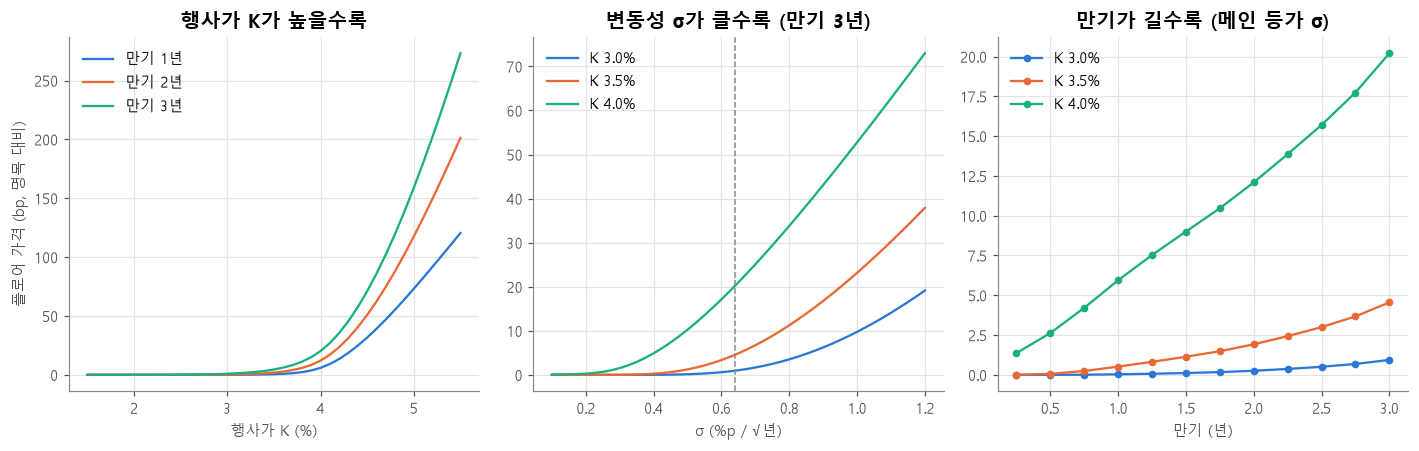

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

# (1) 행사가 K
k_grid = np.linspace(1.5, 5.5, 41)
for T, color in zip(MATURITIES_FLOOR, COLORS):
    prices = [price_floor(curve, K=k, maturity=T, sigma=SIGMA, a=A)[0]["floor"] * 100 for k in k_grid]
    axes[0].plot(k_grid, prices, color=color, label=f"만기 {T}년")
axes[0].set_title("행사가 K가 높을수록")
axes[0].set_xlabel("행사가 K (%)")
axes[0].set_ylabel("플로어 가격 (bp, 명목 대비)")
axes[0].legend(loc="upper left")

# (2) 변동성 σ
s_grid = np.linspace(0.1, 1.2, 45)
for K, color in zip([3.0, 3.5, 4.0], COLORS):
    prices = [price_floor(curve, K=K, maturity=3, sigma=s, a=A)[0]["floor"] * 100 for s in s_grid]
    axes[1].plot(s_grid, prices, color=color, label=f"K {K}%")
axes[1].axvline(SIGMA, color=MUTED, linestyle="--", linewidth=1)
axes[1].set_title("변동성 σ가 클수록 (만기 3년)")
axes[1].set_xlabel("σ (%p / √년)")
axes[1].legend(loc="upper left")

# (3) 만기
t_steps = np.arange(0.25, 3.01, 0.25)
for K, color in zip([3.0, 3.5, 4.0], COLORS):
    prices = [price_floor(curve, K=K, maturity=T, sigma=SIGMA, a=A)[0]["floor"] * 100 for T in t_steps]
    axes[2].plot(t_steps, prices, color=color, marker="o", markersize=4, label=f"K {K}%")
axes[2].set_title("만기가 길수록 (메인 등가 σ)")
axes[2].set_xlabel("만기 (년)")
axes[2].legend(loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "5_floor_sensitivity.png", dpi=200)
plt.show()

**직관적 의미**
- **행사가 K ↑ → 가격 ↑ (점점 가파르게)**: K가 높을수록 더 높은 금리 수준부터 보호해 주는 보험이라 비싸다. 선도금리에서 멀리 떨어진 낮은 K는 거의 공짜에 가깝고, K가 선도금리(4~5%)에 가까워질수록 가격이 **빠르게** 오른다. 보험으로 치면 "자기부담금이 작을수록 보험료가 비싼" 것과 같다.
- **σ ↑ → 가격 ↑**: 금리가 크게 흔들릴수록 K 아래로 떨어질 가능성이 커진다. 지금처럼 외가격인 플로어는 σ에 특히 **민감**하다. σ가 두 배가 되면 가격은 몇 배~수십 배가 된다. σ를 무엇으로 정하느냐가 가격을 크게 좌우하는 이유다.
- **만기 ↑ → 가격 ↑**: 보호받는 분기 수가 늘고, 먼 분기일수록 금리가 흔들릴 시간이 길어 플로어렛 하나하나도 비싸다. 그래서 만기가 2배가 되면 가격은 2배보다 더 커지고, **연간 비용**(6번)도 만기가 길수록 커진다.

## 9. 시장 일치 시뮬레이션과 맞는지 점검

메인 시나리오는 `src/rate_model.py`의 **시장 일치 모형**으로 만든다.

$$r(t) = f(0, t) + x(t), \qquad dx = -a\,x\,dt + \sigma\,dW,\quad x(0) = 0$$

- f(0, t): 위에서 만든 **보정 곡선의 선도금리**
- x(t): 평균 0으로 돌아가는 무작위 충격 (03번 추정값 a = 0.093, σ = 0.64)
- 그래서 경로들의 **평균 = 선도금리**가 되고, 시나리오와 플로어 가격이 같은 기준 위에 선다.

시뮬레이션 분석은 05번에서 한다. 여기서는 함수가 제대로 작동하는지만 두 가지로 확인한다.

### 점검 ① 경로 평균 = 선도금리?
이 셀이 하는 일: 보정 곡선으로 월별 선도금리를 만들고, 경로 20,000개의 달별 평균과 비교한다.

In [15]:
fwd_monthly = monthly_forwards(curve_row.values, MATURITIES, months=36, shift_bp=SHIFT_BP, method="pchip")
check_paths = simulate_market_consistent(fwd_monthly, A, SIGMA, n_paths=20000, seed=42)

gap_mean = np.abs(check_paths.mean(axis=0) - fwd_monthly)
print(f"첫 달 선도금리 {fwd_monthly[0]:.2f}% (현재 SOFR {sofr_today:.2f}%) | 36개월째 {fwd_monthly[-1]:.2f}%")
print(f"경로 평균과 선도금리의 최대 차이: {gap_mean.max():.4f}%p  (0에 가까우면 정상)")

첫 달 선도금리 3.93% (현재 SOFR 3.93%) | 36개월째 4.69%
경로 평균과 선도금리의 최대 차이: 0.0086%p  (0에 가까우면 정상)


### 점검 ② 왜 등가 σ인가 (결정 근거)
시장 일치 모형의 충격 x(t)는 **평균회귀**를 해서, T년 뒤 퍼짐이 σ√T보다 조금 작다.

$$\text{T년 뒤 표준편차} = \sigma\sqrt{\frac{1 - e^{-2aT}}{2a}} = \underbrace{\sigma\sqrt{\frac{1 - e^{-2aT}}{2aT}}}_{\text{등가 σ}} \times \sqrt{T}$$

σ 0.64를 모든 만기에 그대로 쓰면(부록 가격표) 시나리오보다 퍼짐을 크게 보게 된다. 시뮬레이션과 **완전히** 같은 퍼짐을 쓰도록 메인 가격표는 플로어렛마다 이 등가 σ를 넣었다. → **결정: 가격 σ = 등가 σ.**

이 셀이 하는 일: 등가 σ가 만기에 따라 얼마인지 보고, 3년 플로어 가격을 메인(등가 σ)과 부록(σ 0.64 고정)으로 비교한다.

In [16]:
print("등가 σ:", {f"{T}년": round(float(equivalent_sigma(T, A, SIGMA)), 3) for T in [0.5, 1, 2, 3]})

three_year = grid[grid["만기(년)"] == 3].pivot(index="K(%)", columns="설정", values="floor")
sigma_compare = three_year[["▶ 메인: 등가 σ", "부록: σ 0.64 고정"]].copy()
sigma_compare["메인 ÷ 부록 − 1 (%)"] = (sigma_compare.iloc[:, 0] / sigma_compare.iloc[:, 1] - 1) * 100
sigma_compare.index.name = "K(%) · 만기 3년"
sigma_compare

등가 σ: {'0.5년': 0.625, '1년': 0.611, '2년': 0.585, '3년': 0.56}


설정,▶ 메인: 등가 σ,부록: σ 0.64 고정,메인 ÷ 부록 − 1 (%)
K(%) · 만기 3년,,,
1.5000,0.0000,0.0002,-80.5262
2.0000,0.0002,0.0008,-71.1736
2.5000,0.0017,0.0041,-59.5447
3.0000,0.0094,0.0174,-46.0068
3.5000,0.0455,0.0664,-31.4214


**읽는 법**
- **점검 ①**: 경로 평균이 선도금리와 0.01%p 안에서 같다. 첫 달 선도금리도 3.93%로 현재 SOFR와 같다. 함수가 의도대로 작동한다.
- **점검 ②**: 평균회귀 때문에 등가 σ는 1년 0.61, 3년 0.56으로 0.64보다 작다. 그래서 메인(등가 σ) 3년 플로어는 σ 0.64 고정보다 **31~80% 싸다**(외가격일수록 차이가 크다). σ 0.64 고정 가격은 시나리오보다 퍼짐을 크게 본 값이라 부록용으로만 남긴다.

## 10. 정리

**메인 설정**: 미국채 곡선 − 18bp(1개월 국채 − SOFR) + PCHIP 보간, 바슐리에 + **등가 σ**(σ 0.64, a 0.093). 첫 달 선도금리 = 현재 SOFR 3.93%.

**메인 가격 요약 (명목 100 기준)**

| | 1년 | 3년 | 3년 연간 비용 |
|---|---|---|---|
| K 3.5% | 0.005 | 0.046 | 연 1.5bp |
| K 3.0% | 0.0003 | 0.009 | 연 0.3bp |
| K 2.5% 이하 | ≈ 0 | 0.002 이하 | 연 0.06bp 이하 |

- **지금은 플로어가 싸다.** 보정 후에도 선도금리(4.0~4.8%)가 모든 행사가보다 높다. 시장은 금리 상승을 반영하고 있다.
- **만기에 따라 연간 비용이 크게 다르다.** 같은 K 3.5%라도 1년은 연 0.5bp, 3년은 연 1.5bp다.
- 모든 조합에서 프리미엄이 **거래비용(연 2bp)**보다 작다.
- 부록: σ 0.64 고정 가격표(평균회귀 무시)는 메인보다 31~80% 비싸다. σ 0.32 고정은 거의 0이다.

**한계 (기록)**
1. **국채−SOFR 보정이 단순하다**: 모든 만기에서 차이가 18bp로 같다고 본다. 보정 폭이 가격을 크게 바꾼다(3개월 기준 29bp면 3년·K 3.5%가 0.046 → 0.063).
2. **이표채 수익률을 영금리로 근사, 분기 = 0.25년**: 3년 이내·완만한 곡선이라 오차는 몇 bp 수준으로 본다.
3. **SOFR 후취 정산을 "T = 분기 시작 + 분기/3"로 근사**했다.
4. **σ 하나로 모든 행사가를 계산**: 실제 시장에서는 행사가마다 변동성이 다르다(변동성 스마일). 또 과거 데이터로 추정한 σ라서 시장 내재변동성과 다를 수 있다.